In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
import cmocean

In [4]:
import matplotlib as m
import matplotlib.patches as mpatches

In [5]:
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
import cmocean

In [8]:
mswep_jja = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/mswep_jja_avg_202003_202102.nc').__xarray_dataarray_variable__)/30
mswep_djf = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/mswep_djf_avg_202003_202102.nc').__xarray_dataarray_variable__)/30

mswep_jja.coords['longitude'] = (mswep_jja.coords['longitude'] % 360)
mswep_jja = mswep_jja.sortby(mswep_jja.longitude)
mswep_djf.coords['longitude'] = (mswep_djf.coords['longitude'] % 360)
mswep_djf = mswep_djf.sortby(mswep_djf.longitude)

In [39]:
mswep_jja = mswep_jja.rename(dict(longitude='lon', latitude='lat'))
mswep_djf = mswep_djf.rename(dict(longitude='lon', latitude='lat'))

In [9]:
gpcp_jja = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/gpcp_jja_avg_202003_202102.nc').__xarray_dataarray_variable__)*86400
gpcp_djf = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/gpcp_djf_avg_202003_202102.nc').__xarray_dataarray_variable__)*86400

gpcp_jja.coords['longitude'] = (gpcp_jja.coords['longitude'] % 360)
gpcp_jja = gpcp_jja.sortby(gpcp_jja.longitude)
gpcp_djf.coords['longitude'] = (gpcp_djf.coords['longitude'] % 360)
gpcp_djf = gpcp_djf.sortby(gpcp_djf.longitude)

In [40]:
gpcp_jja = gpcp_jja.rename(dict(longitude='lon', latitude='lat'))
gpcp_djf = gpcp_djf.rename(dict(longitude='lon', latitude='lat'))

In [10]:
era_jja = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/era5_jja_avg_202003_202102.nc').tp*1000)
era_djf = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/era5_djf_avg_202003_202102.nc').tp*1000)

In [42]:
era_jja = era_jja.rename(dict(longitude='lon', latitude='lat'))
era_djf = era_djf.rename(dict(longitude='lon', latitude='lat'))

In [38]:
access_amip_jja = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/access_amip_ensemble_jja_avg_200703_200802.nc'))
access_amip_djf = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/access_amip_ensemble_djf_avg_200703_200802.nc'))

In [12]:
access_cmip_jja = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/access_cmip_ensemble_jja_avg.nc'))
access_cmip_djf = (xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/access_cmip_ensemble_djf_avg.nc'))

In [13]:
um_jja = xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/UM_jja_avg_202003_202102.nc')
um_djf = xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/UM_djf_avg_202003_202102.nc')

In [14]:
icon_jja = xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/ICON_jja_avg_202003_202102.nc')
icon_djf = xr.open_dataset('/g/data/if69/as8561/data/hk25-ConvZones/ICON_djf_avg_202003_202102.nc')

In [77]:
import xesmf as xe

In [87]:
regridder = xe.Regridder(access_amip_jja, era_jja, method='bilinear')

In [88]:
access_amip_regrid_jja = regridder(access_amip_jja.pr*86400)
access_amip_regrid_djf = regridder(access_amip_djf.pr*86400)

In [89]:
access_cmip_regrid_jja = regridder(access_cmip_jja.pr*86400)
access_cmip_regrid_djf = regridder(access_cmip_djf.pr*86400)

In [90]:
def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 14, 'color': 'k'}
    gl.ylabel_style = {'size': 14, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, cbar_orientation='vertical', hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160)):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
        # ax.set_aspect('auto')
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i], fontsize=16)
        if draw_winds:
            axlist[i].quiver(x[::3, ::3], y[::3, ::3], u_wnd[i].to_numpy()[::3, ::3], v_wnd[i].to_numpy()[::3, ::3], scale=wind_scale, color='k', transform=ccrs.PlateCarree())
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0))
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':16})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = cbar_orientation, shrink=0.8, aspect = 45, pad = 0.05, label = cbar_label)

In [91]:
gpcp_monsoon_zones = xr.where(np.abs(gpcp_jja.where(gpcp_jja >= 0) - gpcp_djf.where(gpcp_djf >= 0)) > 2.5, 1, np.nan)
mswep_monsoon_zones = xr.where(np.abs(mswep_jja.where(mswep_jja >= 0) - mswep_djf.where(mswep_djf >= 0)) > 2.5, 1, np.nan)
era_monsoon_zones = xr.where(np.abs(era_jja.where(era_jja >= 0) - era_djf.where(era_djf >= 0)) > 2.5, 1, np.nan)

In [162]:
plot_list = [
    gpcp_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
    mswep_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
    era_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
]

In [163]:
title_list = [
    'GPCP',
    'MSWEP',
    'ERA5',
]

In [164]:
label_list = [
    'a',
    'b',
    'c'
]

In [165]:
xx, yy = np.meshgrid(era_jja.sel(lat = slice(40, 5), lon = slice(60, 140)).lon, era_jja.sel(lat = slice(40, 5), lon = slice(60, 140)).lat)

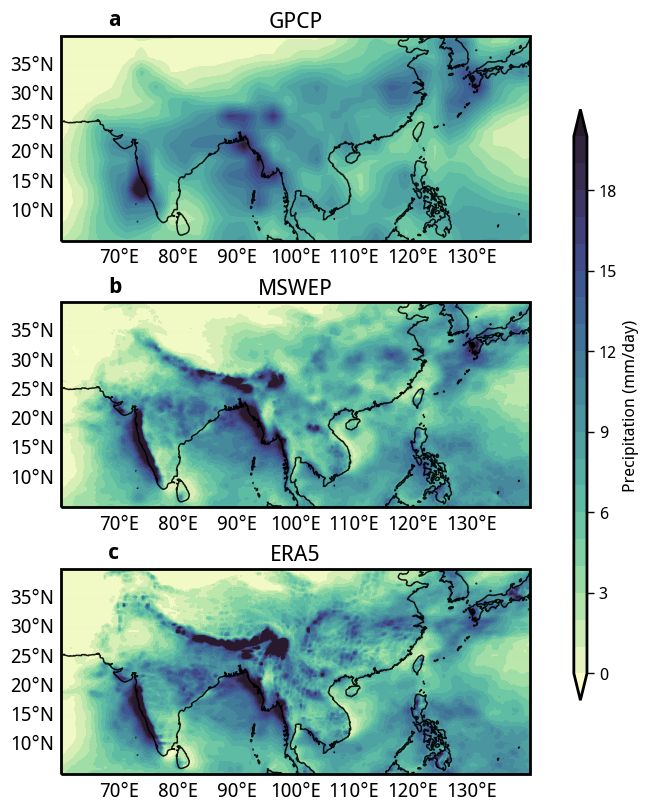

In [166]:
plot_maps(xx, yy, plot_list, title_list, label_list, cmap=cmocean.cm.deep, levels = np.arange(0, 21, 1), cbar_label = 'Precipitation (mm/day)', pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', nrows=3, ncols=1, figsize=(10,8), land_mask_list = [], add_patch=False, add_patch_extra=False, cbar_orientation='vertical', hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=160))

In [167]:
plot_list = [
    era_jja.sel(lat = slice(40, 5), lon=slice(60, 140)) - mswep_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
    (access_amip_regrid_jja).sel(lat = slice(40, 5), lon=slice(60, 140)).mean('run') - mswep_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
    (icon_jja.pr*86400).sel(lat = slice(40, 5), lon=slice(60, 140)) - mswep_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
    (um_jja.pr*86400).sel(lat = slice(40, 5), lon=slice(60, 140)) - mswep_jja.sel(lat = slice(40, 5), lon=slice(60, 140)),
]

In [168]:
title_list = [
    'ERA bias',
    'ACCESS AMIP',
    'ICON',
    'UM'
]

In [169]:
label_list = [
    'a',
    'b',
    'c',
    'd'
]

In [171]:
xx, yy = np.meshgrid(era_jja.sel(lat = slice(40, 5), lon = slice(60, 140)).lon, era_jja.sel(lat = slice(40, 5), lon = slice(60, 140)).lat)

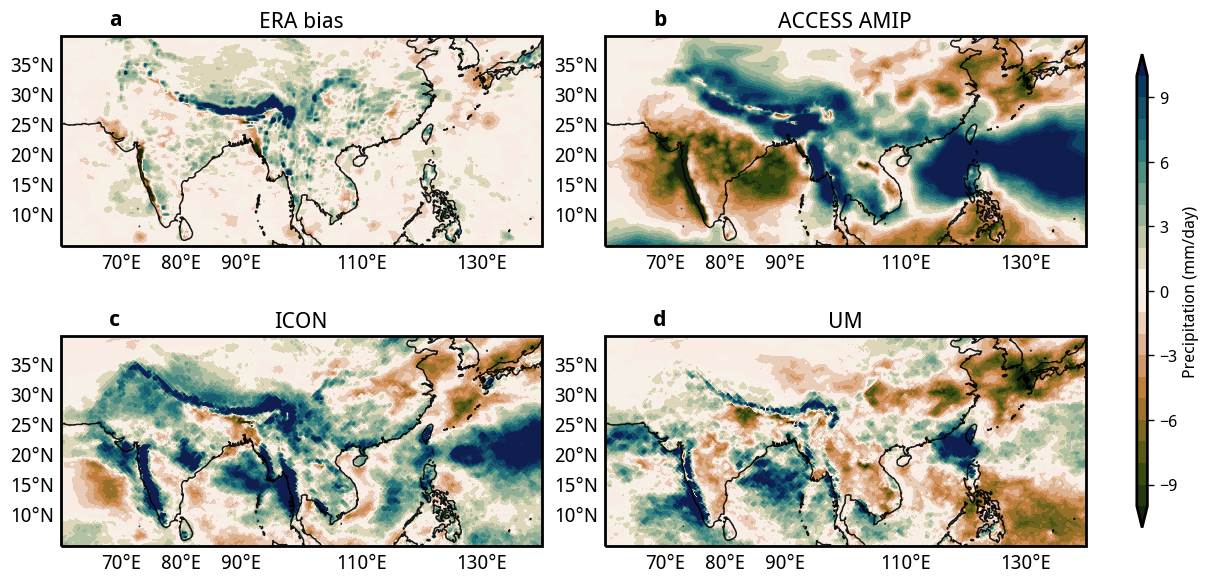

In [173]:
plot_maps(xx, yy, plot_list, title_list, label_list, cmap=cmocean.cm.tarn, levels = np.arange(-10, 11, 1), cbar_label = 'Precipitation (mm/day)', pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', nrows=2, ncols=2, figsize=(12,6), land_mask_list = [], add_patch=False, add_patch_extra=False, cbar_orientation='vertical', hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=160))

In [174]:
plot_list = [
    gpcp_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
    mswep_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
    era_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
]

In [175]:
title_list = [
    'GPCP',
    'MSWEP',
    'ERA5',
]

In [176]:
label_list = [
    'a',
    'b',
    'c'
]

In [177]:
xx, yy = np.meshgrid(era_djf.sel(lat = slice(20, -50), lon = slice(100, 179)).lon, era_djf.sel(lat = slice(20, -50), lon = slice(100, 179)).lat)

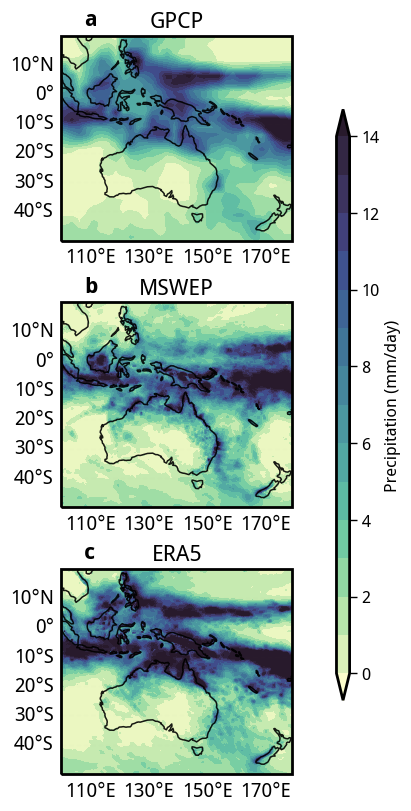

In [178]:
plot_maps(xx, yy, plot_list, title_list, label_list, cmap=cmocean.cm.deep, levels = np.arange(0, 15, 1), cbar_label = 'Precipitation (mm/day)', pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', nrows=3, ncols=1, figsize=(10,8), land_mask_list = [], add_patch=False, add_patch_extra=False, cbar_orientation='vertical', hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=160))

In [179]:
plot_list = [
    era_djf.sel(lat = slice(20, -50), lon=slice(100, 179)) - mswep_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
    (access_amip_regrid_djf).sel(lat = slice(20, -50), lon=slice(100, 179)).mean('run') - mswep_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
    (icon_djf.pr*86400).sel(lat = slice(20, -50), lon=slice(100, 179)) - mswep_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
    (um_djf.pr*86400).sel(lat = slice(20, -50), lon=slice(100, 179)) - mswep_djf.sel(lat = slice(20, -50), lon=slice(100, 179)),
]

In [180]:
title_list = [
    'ERA bias',
    'ACCESS AMIP',
    'ICON',
    'UM'
]

In [181]:
label_list = [
    'a',
    'b',
    'c',
    'd'
]

In [182]:
xx, yy = np.meshgrid(era_jja.sel(lat = slice(20, -50), lon = slice(100, 179)).lon, era_jja.sel(lat = slice(20, -50), lon = slice(100, 179)).lat)

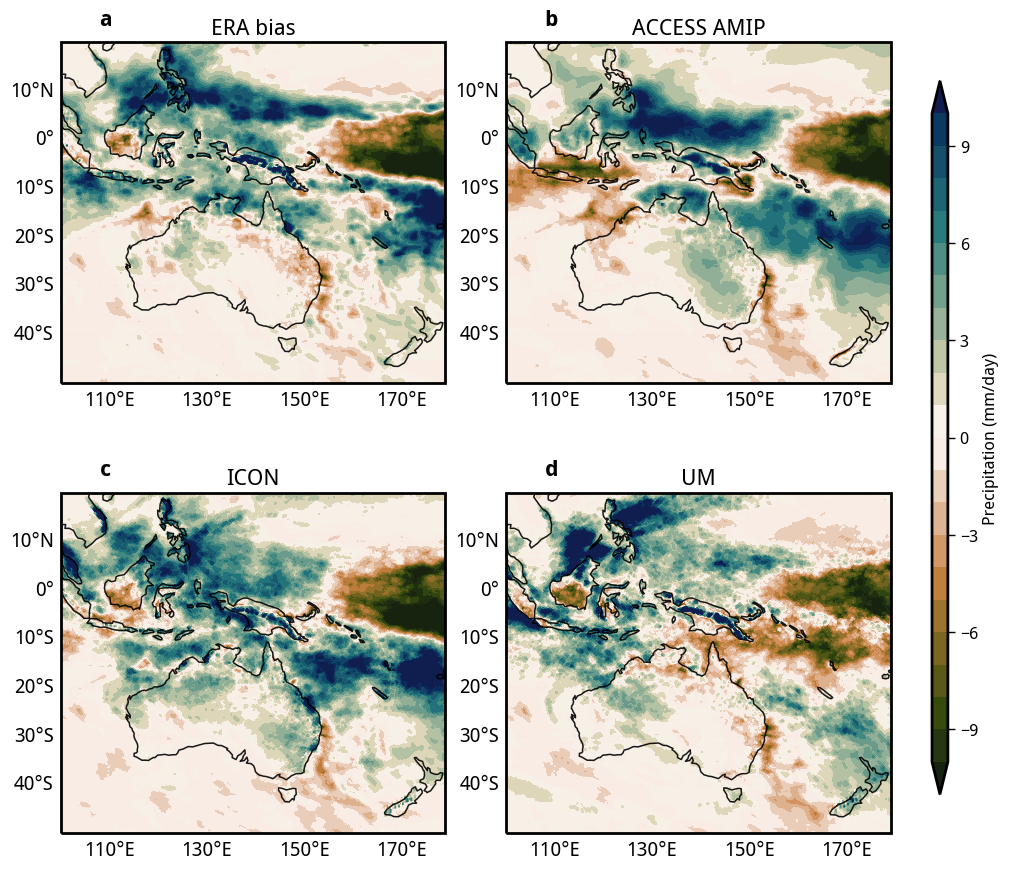

In [184]:
plot_maps(xx, yy, plot_list, title_list, label_list, cmap=cmocean.cm.tarn, levels = np.arange(-10, 11, 1), cbar_label = 'Precipitation (mm/day)', pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', nrows=2, ncols=2, figsize=(10,9), land_mask_list = [], add_patch=False, add_patch_extra=False, cbar_orientation='vertical', hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=160))